In [1]:
import pandas as pd
from pathlib import Path

In [6]:
data = 'toy_spread_funding_two_products.csv'
df = pd.read_csv(data).set_index('timestamp_utc')
df.index = pd.to_datetime(df.index)
df.head()

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,perp_ask,perp_mark_price,index_price,usdc_usdt,funding_rate_8h,funding_event,spot_volume_usd,perp_volume_usd,open_interest_usd
timestamp_utc,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,80138.09,80113.00,80007.17,1.000090,0.000042,0,8.058144e+07,2.109624e+08,1.791965e+09
2026-09-15 00:00:00+00:00,ETH,ETH-USDT,ETH-USDT-PERP,USDT,USDT,10.0,-10.0,3199.59,3200.41,3202.18,3202.69,3202.14,3200.00,1.000000,0.000028,0,3.551676e+07,1.824232e+08,8.891708e+08
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,80017.09,79989.72,79870.32,1.000250,0.000051,0,9.720665e+07,1.224543e+08,1.796887e+09
2026-09-15 01:00:00+00:00,ETH,ETH-USDT,ETH-USDT-PERP,USDT,USDT,10.0,-10.0,3196.13,3196.87,3200.53,3200.95,3200.23,3196.50,1.000000,0.000033,0,5.319370e+07,1.598502e+08,9.016021e+08
2026-09-15 02:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79945.97,79970.67,80112.17,80121.18,80095.28,79974.08,1.000197,0.000039,0,1.206133e+08,2.960957e+08,1.797561e+09


In [7]:
df_btc = df[df['product'] == 'BTC']
df_btc.head()

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,perp_ask,perp_mark_price,index_price,usdc_usdt,funding_rate_8h,funding_event,spot_volume_usd,perp_volume_usd,open_interest_usd
timestamp_utc,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,80138.09,80113.00,80007.17,1.000090,0.000042,0,8.058144e+07,2.109624e+08,1.791965e+09
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,80017.09,79989.72,79870.32,1.000250,0.000051,0,9.720665e+07,1.224543e+08,1.796887e+09
2026-09-15 02:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79945.97,79970.67,80112.17,80121.18,80095.28,79974.08,1.000197,0.000039,0,1.206133e+08,2.960957e+08,1.797561e+09
2026-09-15 03:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,80085.01,80102.60,80269.65,80280.16,80250.78,80114.06,1.000253,0.000038,0,5.868380e+07,1.812772e+08,1.804674e+09
2026-09-15 04:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79806.04,79819.99,80015.51,80019.51,79988.14,79821.70,1.000109,0.000046,0,8.136117e+07,1.854489e+08,1.824991e+09


In [8]:
# Question 1: Mid price calculations for both Spot and Perp. Then, raw spread calculation and basis in bps. 

<Axes: xlabel='timestamp_utc'>

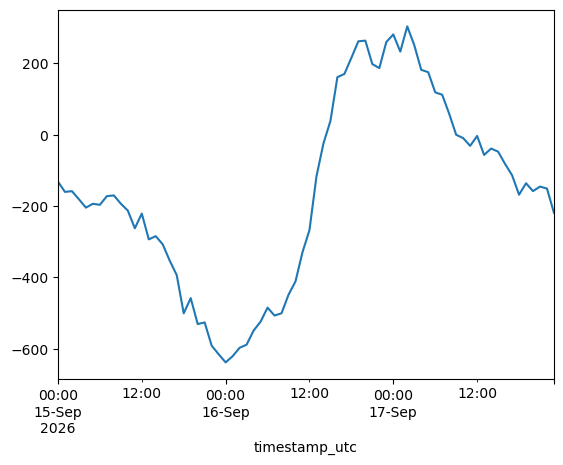

In [25]:
df_btc['Spot_Mid'] = (df_btc['spot_ask'] + df_btc['spot_bid']) / 2
df_btc['Perp_Mid'] = (df_btc['perp_ask'] + df_btc['perp_bid']) / 2
df_btc['Basis'] = df_btc['Spot_Mid'] - df_btc['Perp_Mid']
df_btc['BasisInBPS'] = (df_btc['Basis'] / ((df_btc['Spot_Mid'] + df_btc['Perp_Mid']) / 2) ) * 10_000
df_btc['Basis'].plot()

In [26]:
df_btc.head()

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,...,usdc_usdt,funding_rate_8h,funding_event,spot_volume_usd,perp_volume_usd,open_interest_usd,Spot_Mid,Perp_Mid,Basis,BasisInBPS
timestamp_utc,,,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,...,1.000090,0.000042,0,8.058144e+07,2.109624e+08,1.791965e+09,80000.000,80131.675,-131.675,-16.445841
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,...,1.000250,0.000051,0,9.720665e+07,1.224543e+08,1.796887e+09,79850.380,80010.790,-160.410,-20.068663
2026-09-15 02:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79945.97,79970.67,80112.17,...,1.000197,0.000039,0,1.206133e+08,2.960957e+08,1.797561e+09,79958.320,80116.675,-158.355,-19.785101
2026-09-15 03:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,80085.01,80102.60,80269.65,...,1.000253,0.000038,0,5.868380e+07,1.812772e+08,1.804674e+09,80093.805,80274.905,-181.100,-22.585453
2026-09-15 04:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79806.04,79819.99,80015.51,...,1.000109,0.000046,0,8.136117e+07,1.854489e+08,1.824991e+09,79813.015,80017.510,-204.495,-25.588979


In [ ]:
# convert BTC-USDC to BTC-USDT using exchange rate USDC-USDT 
# Sell USDC, Buy USDT. So, 'short' USDC-USDT. 

df_btc['spot_bid'] * df_btc['usdc_usdt']